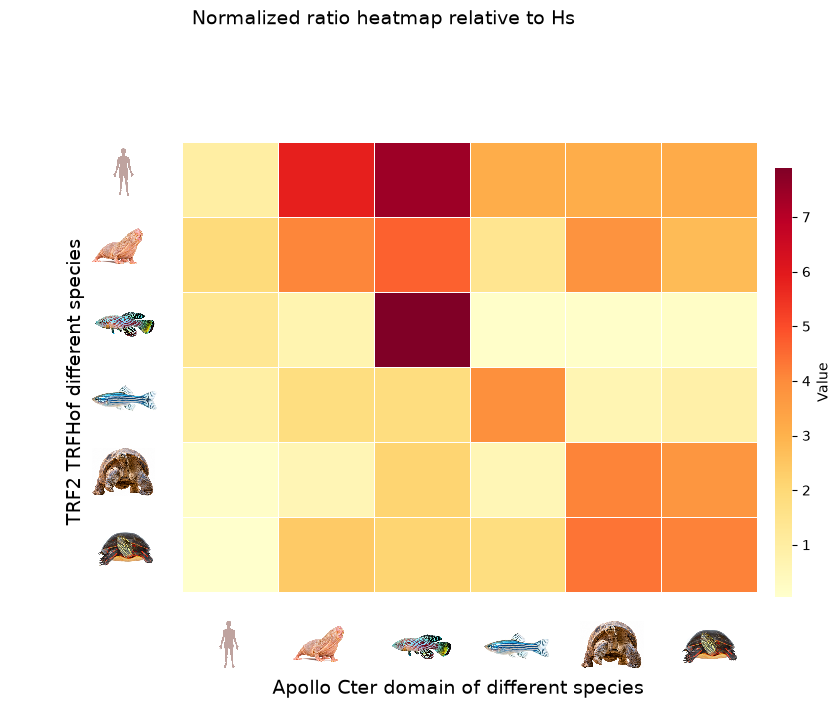

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

rows = ['Hs TRF2 TRFH','Hg TRF2 TRFH','Nf TRF2 TRFH','Dr TRF2 TRFH','Ca TRF2 TRFH','Cp TRF2 TRFH']
cols = ['Hs Apollo Cter','Hg Apollo Cter','Nf Apollo Cter','Dr Apollo Cter','Ca Apollo Cter','Cp Apollo Cter']

data = [
    [1, 5.8294073721023, 7.416571743, 3.148635755, 3.14742025, 3.208357],
    [1.922430028, 4.0873202528942,4.682669049, 1.403529333, 3.823791673, 2.762898],
    [1.364981598, 0.696518517,7.905123916,  0.144056154, 0.144056154, 0.194712],
    [0.960945038, 1.775153086,1.813002345,  3.903317492, 0.611428633, 0.867945],
    [0.172644532, 0.574859316, 2.113328706, 0.546394337, 4.125052211, 3.75307],
    [0.053297088, 2.387636816, 2.113328706, 1.775037454, 4.37510109, 4.148218],
]

df = pd.DataFrame(data, index=rows, columns=cols)

fig, ax = plt.subplots(figsize=(15, 10))
sns.heatmap(df,
    annot=False,
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={
        'label': 'Value',
        'shrink': 0.65,   # làm thanh màu ngắn lại
        'aspect': 25,    # làm thanh mảnh hơn
        'pad': 0.02      # sát vào heatmap hơn
    },
    ax=ax
)

ax.set_xticklabels([])
ax.set_yticklabels([])

ax.set_xlabel('Apollo Cter domain of different species', fontsize=14)
ax.set_ylabel('TRF2 TRFHof different species', fontsize=14)

ax.xaxis.set_label_coords(0.6, 0.05)
ax.yaxis.set_label_coords(0.1, 0.5)

ax.set_title('Normalized ratio heatmap relative to Hs', pad=20, fontsize=14)
ax.tick_params(axis='both', which='both', length=0, width=1, direction='out')

# Tăng vùng trống xung quanh heatmap
ax.set_xlim(-1.8, len(cols))
ax.set_ylim(len(rows) + 1.6, -1.2)

row_imgs = ['Hs1.png', 'Hg.png', 'Nf.png', 'Dr.png', 'Ca.png', 'Cp.png']
col_imgs = ['Hs1.png', 'Hg.png', 'Nf.png', 'Dr.png', 'Ca.png', 'Cp.png']

# Ảnh hàng: đẩy sang trái
for i, img_file in enumerate(row_imgs):
    img = Image.open(img_file).convert('RGBA')
    im = OffsetImage(img, zoom=0.05)
    ab = AnnotationBbox(im, (-0.6, i + 0.4), xycoords='data', frameon=False)
    ab.set_clip_on(False)
    ax.add_artist(ab)

# Ảnh cột: đẩy xuống dưới
for j, img_file in enumerate(col_imgs):
    img = Image.open(img_file).convert('RGBA')
    im = OffsetImage(img, zoom=0.05)
    ab = AnnotationBbox(im, (j + 0.5, len(rows) + 0.7), xycoords='data', frameon=False)
    ab.set_clip_on(False)
    ax.add_artist(ab)

plt.subplots_adjust(left=0.2, right=0.8, top=0.88, bottom=0.22)
plt.show()


In [2]:
fig.savefig("Heat map.png", dpi=600, bbox_inches="tight", pad_inches=0.1)


In [3]:
import pandas as pd

rows = ['Hs TRF2 TRFH', 'Hg TRF2 TRFH', 'Dr TRF2 TRFH', 'Nf TRF2 TRFH', 'Ca TRF2 TRFH', 'Cp TRF2 TRFH']
cols = ['Hs Apollo Cter', 'Hg Apollo Cter', 'Dr Apollo Cter', 'Nf Apollo Cter', 'Ca Apollo Cter', 'Cp Apollo Cter']

average = [
    [1, 5.8294073721023, 3.148635755, 7.416571743, 3.14742025, 3.208357],
    [1.922430028, 4.0873202528942, 1.403529333, 4.682669049, 3.823791673, 2.762898],
    [0.960945038, 1.775153086, 3.903317492, 1.813002345, 0.611428633, 0.867945],
    [1.364981598, 0.696518517, 0.144056154, 7.905123916, 0.144056154, 0.194712],
    [0.172644532, 0.574859316, 0.546394337, 2.113328706, 4.125052211, 3.75307],
    [0.053297088, 2.387636816, 1.775037454, 2.113328706, 4.37510109, 4.148218],
]

sd = [
    [0.13955531501634, 0.497320321, 1.904484412, 1.279807054, 0.989170482, 1.081573],
    [0.762980237, 0.660716064166307, 0.468353483, 0.938872885, 1.426184969, 1.634007],
    [0.860589511, 0.352474159, 0.8319564, 1.217811244, 0.278302101, 0.342443],
    [0.266209349, 0.183879842, 0.062200813, 2.180656653, 0.122174917, 0.270142],
    [0.150830143, 0.49002047, 0.025065378, 0.282830169, 0.527604161, 0.60102],
    [0.046663498, 0.910048071, 0.63070567, 1.416791118, 1.761673897, 1.53078],
]

def fmt(x):
    return f"{x:.2f}".replace('.', ',')

table = [
    [f"{fmt(m)} ± {fmt(s)}" for m, s in zip(m_row, s_row)]
    for m_row, s_row in zip(average, sd)
]

df = pd.DataFrame(table, index=rows, columns=cols)
df

,Hs Apollo Cter,Hg Apollo Cter,Dr Apollo Cter,Nf Apollo Cter,Ca Apollo Cter,Cp Apollo Cter
Hs TRF2 TRFH,"1,00 ± 0,14","5,83 ± 0,50","3,15 ± 1,90","7,42 ± 1,28","3,15 ± 0,99","3,21 ± 1,08"
Hg TRF2 TRFH,"1,92 ± 0,76","4,09 ± 0,66","1,40 ± 0,47","4,68 ± 0,94","3,82 ± 1,43","2,76 ± 1,63"
Dr TRF2 TRFH,"0,96 ± 0,86","1,78 ± 0,35","3,90 ± 0,83","1,81 ± 1,22","0,61 ± 0,28","0,87 ± 0,34"
Nf TRF2 TRFH,"1,36 ± 0,27","0,70 ± 0,18","0,14 ± 0,06","7,91 ± 2,18","0,14 ± 0,12","0,19 ± 0,27"
Ca TRF2 TRFH,"0,17 ± 0,15","0,57 ± 0,49","0,55 ± 0,03","2,11 ± 0,28","4,13 ± 0,53","3,75 ± 0,60"
Cp TRF2 TRFH,"0,05 ± 0,05","2,39 ± 0,91","1,78 ± 0,63","2,11 ± 1,42","4,38 ± 1,76","4,15 ± 1,53"
